# Implementação de Gradient Boost

## Importações iniciais

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [72]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.datasets import load_breast_cancer, make_classification
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

## Implementação do modelo utilizando a clase `DecisionTreeRegressor`

In [73]:
class GradientBoost:
    def __init__(self, learning_rate, max_depth: int, random_state: int, num_estimators: int=100):
        self.num_estimators = num_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.random_state = random_state
    
    def fit(self, X, y):
        self.trees = []
        p = np.mean(y)
        self.valor_inicial = np.log(p/(1-p+1e-10))
        previsoes = [self.valor_inicial for _ in range(len(X))]

        for _ in range(self.num_estimators):
            probabilidades = [self._sigmoide(log_odd) for log_odd in previsoes]
            residuos = [y_i-p_i for y_i,p_i in zip(y,probabilidades)]
            arvore = DecisionTreeRegressor(random_state=self.random_state,max_depth=self.max_depth)
            arvore.fit(X, residuos)
            y_pred = arvore.predict(X)
            previsoes = [pred+self.learning_rate*y_pre_i for pred,y_pre_i in zip(previsoes, y_pred)]
            self.trees.append(arvore)
    
    def _predict_prob(self, X):
        previsoes = [self.valor_inicial for _ in range(len(X))]
        for i in range(len(self.trees)):
            y_pred = self.trees[i].predict(X)
            previsoes = [p+yp*self.learning_rate for p,yp in zip(previsoes, y_pred)]
        probabilidades = [self._sigmoide(p) for p in previsoes]
        return probabilidades
    
    def predict(self, X):
        probs = self._predict_prob(X)
        return [1 if p>=0.5 else 0 for p in probs]
    
    @staticmethod
    def _sigmoide(val: float | int)->float:
        return 1/(1+np.exp(-val))

## Divisão Breast Cancer

In [74]:
X, y = load_breast_cancer(return_X_y=True, as_frame=True)

In [75]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

## Modelagem Dataset Iris

In [76]:
gbt = GradientBoost(learning_rate=0.1, max_depth=3, random_state=0, num_estimators=100)
Gbt = GradientBoostingClassifier(learning_rate=0.1, max_depth=3, random_state=0, n_estimators=100)

In [77]:
gbt.fit(X_train, y_train)
Gbt.fit(X_train, y_train)

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are'friedman_mse' for the mean squared error with improvement score byFriedman, 'squared_error' for mean squared error. The default value of'friedman_mse' is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, 

In [78]:
y_pred = gbt.predict(X_test)
y_pred_sklearn = Gbt.predict(X_test)

In [79]:
print(f"Acurácia: {accuracy_score(y_test, y_pred):.2f}\nAcurácia (sklearn): {accuracy_score(y_test, y_pred_sklearn):.2f}")
print(f"Precisão: {precision_score(y_test, y_pred):.2f}\nPrecisão (sklearn): {precision_score(y_test, y_pred_sklearn):.2f}")
print(f"Revocação: {recall_score(y_test, y_pred):.2f}\nRevocação (sklearn): {recall_score(y_test, y_pred_sklearn):.2f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.2f}\nF1 Score (sklearn): {f1_score(y_test, y_pred_sklearn):.2f}")

Acurácia: 0.97
Acurácia (sklearn): 0.96
Precisão: 0.97
Precisão (sklearn): 0.97
Revocação: 0.99
Revocação (sklearn): 0.97
F1 Score: 0.98
F1 Score (sklearn): 0.97


## Curva de aprendizado

In [80]:
erros_teste = []
erros_sklearn = []
n_arvores_lista = range(1, gbt.num_estimators + 1)

for n in n_arvores_lista:

    sub_trees = gbt.trees[:n]
    
    previsoes = [gbt.valor_inicial for _ in range(len(X_test))]
    for arvore in sub_trees:
        y_pred_arvore = arvore.predict(X_test)
        previsoes = [p + gbt.learning_rate * yp for p, yp in zip(previsoes, y_pred_arvore)]
    
    probs = [gbt._sigmoide(p) for p in previsoes]
    y_pred = [1 if p >= 0.5 else 0 for p in probs]
    
    acc = accuracy_score(y_test, y_pred)
    erros_teste.append(1 - acc)
for y_pred_iter in Gbt.staged_predict(X_test):
    acc_sklearn = accuracy_score(y_test, y_pred_iter)
    erros_sklearn.append(1 - acc_sklearn)

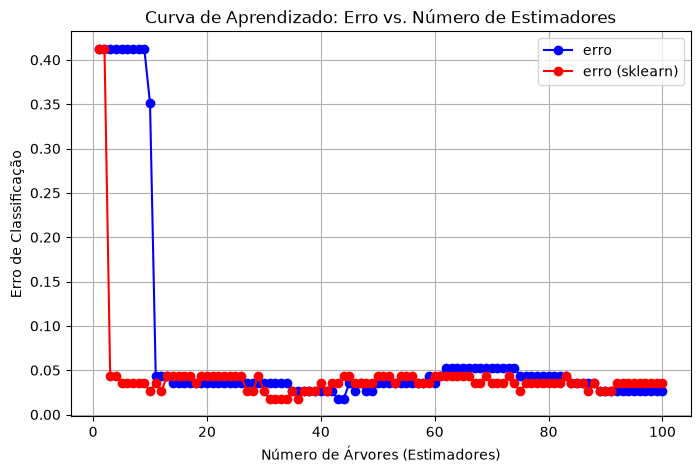

In [81]:
plt.figure(figsize=(8, 5))
plt.plot(n_arvores_lista, erros_teste, marker='o', linestyle='-', color='b',label="erro")
plt.plot(range(1, len(erros_sklearn) + 1), erros_sklearn, marker='o', linestyle='-', color='r', label="erro (sklearn)")
plt.title('Curva de Aprendizado: Erro vs. Número de Estimadores')
plt.xlabel('Número de Árvores (Estimadores)')
plt.ylabel('Erro de Classificação')
plt.legend()
plt.grid(True)
plt.show()

Como podemos ver nas curvas de aprendizado, a implementação do sklearn teve uma variação levemente menor que a implementação local, possivelmente devido a técnicas de otimização e outras nuances na implementação.